# Floatmatcher quickstart

`set_points` → `set_product` → `set_method` → `match` → `reinject`

In [4]:
import numpy as np
import pandas as pd
import cdsapi
import matplotlib.pyplot as plt

from floatmatcher.floatmatcher import FloatMatcher

### Points

In [5]:
# a few positions in the North Atlantic, early January 2018
df = pd.DataFrame({
    "longitude": [-38.2, -35.6, -31.9, -27.4, -23.1],
    "latitude":  [31.5, 34.2, 37.8, 40.1, 43.6],
    "date": pd.to_datetime(["2018-01-02 03:10", "2018-01-03 14:45", "2018-01-05 08:20",
                            "2018-01-06 21:05", "2018-01-08 11:30"]),
})

my_fm = FloatMatcher()
my_fm.set_points(df)  # columns longitude, latitude, date by default
df

,longitude,latitude,date
0,-38.2,31.5,2018-01-02 03:10:00
1,-35.6,34.2,2018-01-03 14:45:00
2,-31.9,37.8,2018-01-05 08:20:00
3,-27.4,40.1,2018-01-06 21:05:00
4,-23.1,43.6,2018-01-08 11:30:00


### Product

In [7]:
my_fm.set_product(type="era5-hourly",
                  source="remote-cds",                # downloaded from the Copernicus Climate Data Store
                  path="./cache",                     # cache directory, reused between sessions
                  selected_variables=["sst"],
                  client=cdsapi.Client(),             # key in ~/.cdsapirc, see https://cds.climate.copernicus.eu/how-to-api
                  time=["00:00", "06:00", "12:00", "18:00"],  # hours to download, all of them by default
                  )

# local files instead:
# my_fm.set_product(type="era5-hourly", source="local", path="/<era5_folder>", selected_variables=["sst"])

2026-11-06 23:08:56,717 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


### Method

In [8]:
my_fm.set_method(type="nearest",
                 radius=25,                         # km
                 time_gap=np.timedelta64(6, "h"),
                 )

### Matchup

In [9]:
my_fm.match()  # downloads what is missing in the cache, then matches
my_fm.result

2026-11-06 23:09:00,435 INFO Request ID is d18b2c2d-3267-450c-8cdf-49df2e456b75
2026-11-06 23:09:00,555 INFO status has been updated to successful



    variables: dict_keys(['sst'])                 
    mean_dist:10.72 (km)
    mean_time_delta:8160.0 (seconds)                 
    nb_match_found:5

### Results

In [10]:
matched = my_fm.reinject()  # the input DataFrame, with sst_coloc added
matched

,longitude,latitude,date,sst_coloc
0,-38.2,31.5,2018-01-02 03:10:00,295.034180
1,-35.6,34.2,2018-01-03 14:45:00,293.568359
2,-31.9,37.8,2018-01-05 08:20:00,291.394775
3,-27.4,40.1,2018-01-06 21:05:00,290.468750
4,-23.1,43.6,2018-01-08 11:30:00,288.234375


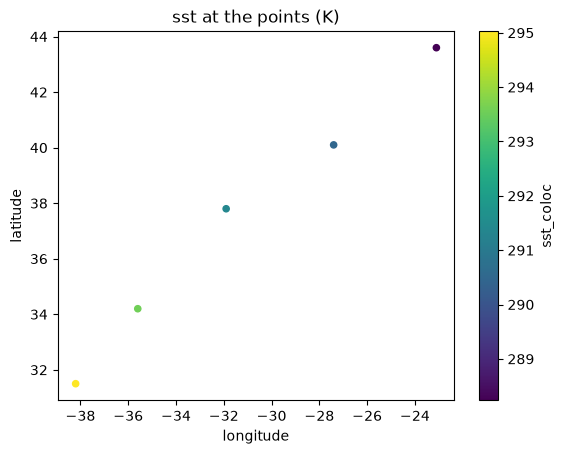

In [11]:
ax = matched.plot.scatter(x="longitude", y="latitude", c="sst_coloc", cmap="viridis")
ax.set_title("sst at the points (K)")
plt.show()